In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import shap
import xgboost as xgb
import optuna
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.feature_selection import RFECV

In [3]:
def gc_stratified_split(df, gc_col, n_bins, random_state, val_size=0.15, test_size=0.15):
    df = df.copy()
    df["_gc_bin"] = pd.qcut(df[gc_col], q=n_bins, labels=False, duplicates="drop")
    train_idx, temp_idx = train_test_split(
        df.index, test_size=val_size + test_size,
        stratify=df["_gc_bin"], random_state=random_state,
    )
    relative_test = test_size / (val_size + test_size)
    val_idx, test_idx = train_test_split(
        temp_idx, test_size=relative_test,
        stratify=df.loc[temp_idx, "_gc_bin"], random_state=random_state,
    )
    return (df.loc[train_idx].drop(columns="_gc_bin"),
            df.loc[val_idx].drop(columns="_gc_bin"),
            df.loc[test_idx].drop(columns="_gc_bin"))

In [4]:
df = pd.read_excel('data_for_regression.xlsx')

In [5]:
FEATURE_COLS = [
    'GC-content', 'Shannon entropy of monomers', 'Shannon entropy of dimers', 
    'Fraction of masked nucleotides', 'Probe intersection percent',
    'Mononucleotide repeat fraction', 'Dinucleotide repeat fraction', 'Trinucleotide repeat fraction',
    'Sum of repeat fractions', 'Off-target count',
    'ΔG of probe hairpins', 'MFE of probe hairpins',
    'ΔG of probe homodimers', 'MFE of probe homodimers',
    'ΔG of probe-target', 'MFE of probe-target',
]

TARGET_COL = 'Median on-target Nbases'
GC_COL = 'GC-content'

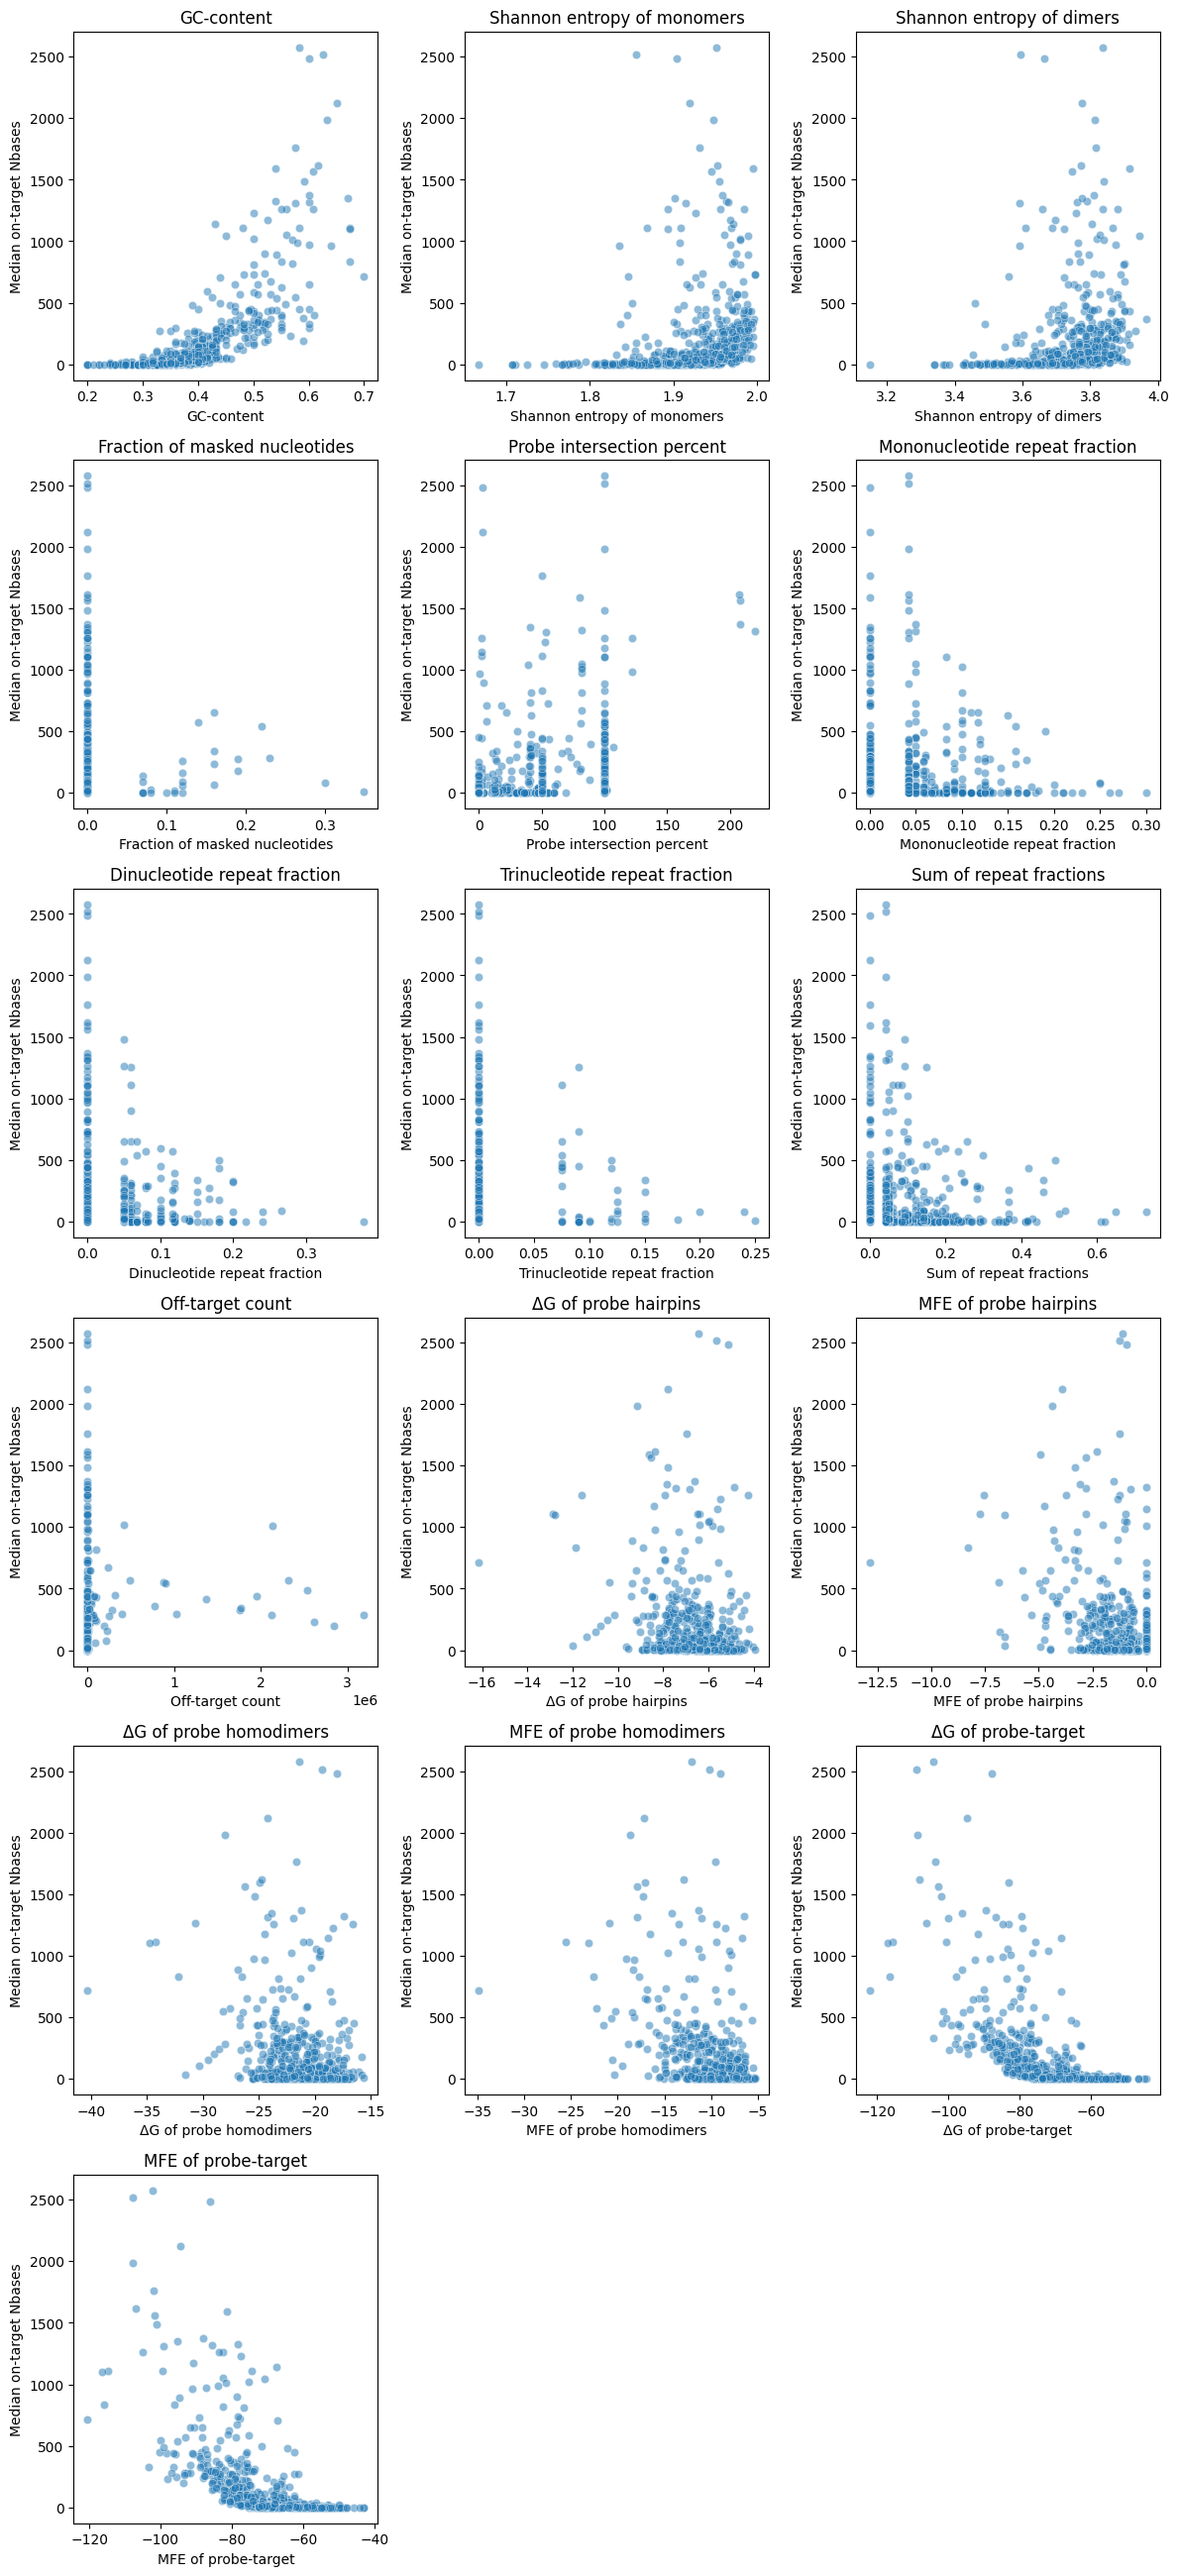

In [20]:
char_cols = FEATURE_COLS + [TARGET_COL]
chars = df[char_cols]

fig, axes = plt.subplots(7, 3, figsize=(12, 30))
axes = axes.ravel()

for i, col in enumerate(chars.columns[:-1]):
    sns.scatterplot(data=chars, x=col, y=TARGET_COL, 
                    ax=axes[i], alpha=0.5)
    axes[i].set_title(col)

for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('figs/svg/scatter_plots_16_features.svg')
plt.savefig('figs/scatter_plots_16_features.png', dpi = 300)

In [7]:
spearman_corr = df[FEATURE_COLS].corr(method="spearman")

threshold = 0.85
collinear_pairs = []
for i in range(len(FEATURE_COLS)):
    for j in range(i + 1, len(FEATURE_COLS)):
        r = spearman_corr.iloc[i, j]
        if abs(r) > threshold:
            collinear_pairs.append((FEATURE_COLS[i], FEATURE_COLS[j], round(r, 3)))

target_corr = {
    feat: abs(stats.spearmanr(df[feat], df[TARGET_COL]).statistic)
    for feat in FEATURE_COLS
}

to_drop = set()
for f1, f2, r in collinear_pairs:
    if f1 in to_drop or f2 in to_drop:
        continue
    drop = f1 if target_corr[f1] < target_corr[f2] else f2
    keep = f2 if drop == f1 else f1
    to_drop.add(drop)

FEATURES_REDUCED = [f for f in FEATURE_COLS if f not in to_drop]
print(f"Removed {len(to_drop)} features due to multicollinearity:"
      f"\n{to_drop}")

Removed 3 features due to multicollinearity:
{'ΔG of probe hairpins', 'Shannon entropy of dimers', 'MFE of probe-target'}


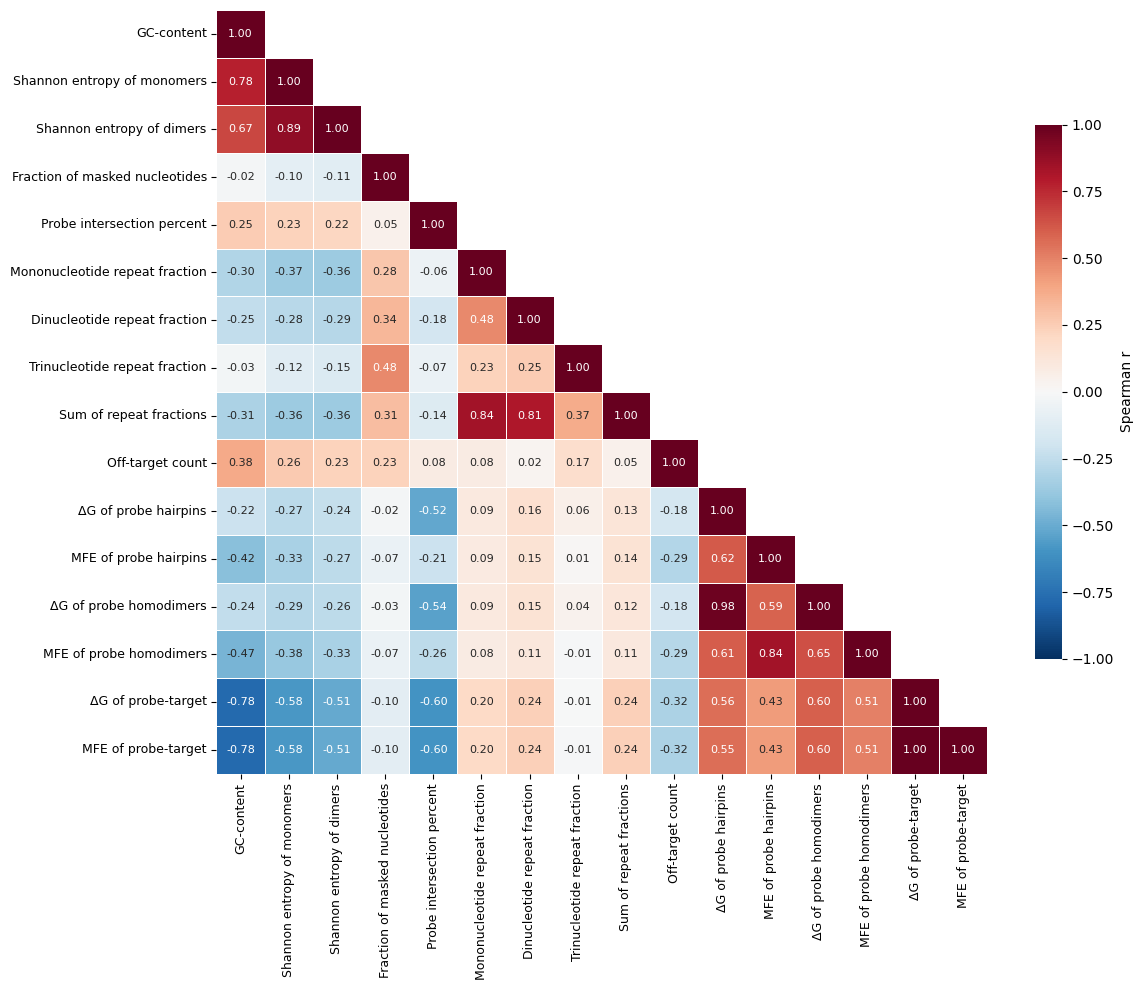

In [19]:
cols_for_heatmap = FEATURE_COLS
corr_df = df[cols_for_heatmap].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.zeros_like(corr_df, dtype=bool)
mask[np.triu_indices_from(mask, k=1)] = True

sns.heatmap(
    corr_df,
    mask=mask,
    annot=True, fmt=".2f", annot_kws={"size": 8},
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    linewidths=0.4, linecolor="white",
    ax=ax,
    cbar_kws={"shrink": 0.7, "label": "Spearman r"},
)

ax.tick_params(axis="x", rotation=90, labelsize=9)
ax.tick_params(axis="y", rotation=0,  labelsize=9)

plt.tight_layout()
plt.savefig("figs/FEATURES_ALL_corr_matrix.png", dpi=300, bbox_inches="tight")
plt.savefig("figs/svg/FEATURES_ALL_corr_matrix.svg", bbox_inches="tight")

In [9]:
N_REPEATS = 100

results = []

for seed in range(N_REPEATS):

    train_df, val_df, test_df = gc_stratified_split(
        df,
        GC_COL,
        n_bins=5,
        random_state=seed
    )

    X_train = train_df[FEATURES_REDUCED].values
    y_train = np.log1p(train_df[TARGET_COL].values)

    rfecv = RFECV(
        estimator=xgb.XGBRegressor(
            random_state=42,
            n_jobs=1,
            verbosity=0
        ),
        step=1,
        cv=KFold(
            n_splits=5,
            shuffle=True,
            random_state=seed
        ),
        scoring="r2",
        min_features_to_select=3,
        n_jobs=-1
    )

    rfecv.fit(X_train, y_train)

    for feature, rank, selected in zip(
        FEATURES_REDUCED,
        rfecv.ranking_,
        rfecv.support_
    ):
        results.append({
            "seed": seed,
            "feature": feature,
            "rank": rank,
            "selected": selected,
            "optimal_n": rfecv.n_features_
        })

results_df = pd.DataFrame(results)

In [10]:
stability_ranking_df = (
    results_df.groupby("feature").agg(
        mean_rank=("rank", "mean"),
        median_rank=("rank", "median"),
        sd_rank=("rank", "std"),

        selection_frequency=("selected", "mean"),
        top5_frequency=(
            "rank",
            lambda x: np.mean(x <= 5)
        )
    ).reset_index()
)

stability_ranking_df = (
    stability_ranking_df.sort_values(
        ["mean_rank", "selection_frequency"],
        ascending=[True, False]
    ).reset_index(drop=True)
)

stability_ranking_df

,feature,mean_rank,median_rank,sd_rank,selection_frequency,top5_frequency
0,GC-content,1.00,1.0,0.000000,1.00,1.00
1,ΔG of probe-target,1.00,1.0,0.000000,1.00,1.00
2,Off-target count,1.03,1.0,0.222702,0.98,1.00
3,Probe intersection percent,1.18,1.0,0.657206,0.92,1.00
4,ΔG of probe homodimers,1.19,1.0,0.917782,0.94,0.99
5,Sum of repeat fractions,1.43,1.0,0.987344,0.79,0.99
6,MFE of probe homodimers,1.55,1.0,1.095215,0.72,0.98
7,MFE of probe hairpins,1.63,1.0,1.345813,0.75,0.96
8,Mononucleotide repeat fraction,1.70,1.0,1.500842,0.75,0.95
9,Dinucleotide repeat fraction,1.96,1.0,1.675251,0.66,0.94


Baseline model - on 13 features before RFECV

In [11]:
X_val = val_df[FEATURES_REDUCED].values
y_val = np.log1p(val_df[TARGET_COL].values)
X_test = test_df[FEATURES_REDUCED].values
y_test = np.log1p(test_df[TARGET_COL].values)

baseline_model = xgb.XGBRegressor(random_state=42, n_jobs=-1,)
baseline_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False,
)
y_pred_log = baseline_model.predict(X_test)

r2_log  = r2_score(y_test, y_pred_log)
spearman_log = stats.spearmanr(y_test, y_pred_log).statistic
rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))

print("BASELINE metrics on test subset:")
print(f"R²   (log1p): {r2_log:.4f}")
print(f"RMSE (log1p): {rmse_log:.4f}")
print(f"Spearman r (log1p): {spearman_log:.4f}")

BASELINE_R2 = r2_log
BASELINE_RMSE = rmse_log

BASELINE metrics on test subset:
R²   (log1p): 0.6942
RMSE (log1p): 1.2091
Spearman r (log1p): 0.8464


Final model - on selected features

In [12]:
#SELECTED_FEATURES = stability_ranking_df[stability_ranking_df["median_rank"] == 1]["feature"].to_list()
SELECTED_FEATURES = stability_ranking_df[stability_ranking_df["selection_frequency"] > 0.7]["feature"].to_list()

X_train_optuna = train_df[SELECTED_FEATURES].values
X_val_final = val_df[SELECTED_FEATURES].values
X_test_final = test_df[SELECTED_FEATURES].values

# log1p transform of target variable
y_train = np.log1p(train_df[TARGET_COL].values)
y_val = np.log1p(val_df[TARGET_COL].values)
y_test = np.log1p(test_df[TARGET_COL].values)

# raw values
y_train_raw = train_df[TARGET_COL].values
y_val_raw = val_df[TARGET_COL].values
y_test_raw = test_df[TARGET_COL].values

print(f"Subset sizes: train={len(X_train)}, val={len(X_val_final)}, test={len(X_test_final)}")
print(f"mean GC-content: train={train_df[GC_COL].mean():.4f}, "
      f"val={val_df[GC_COL].mean():.4f}, test={test_df[GC_COL].mean():.4f}")
print(f"mean y values (log1p): train mean={y_train.mean():.3f}, val mean={y_val.mean():.3f}")

Subset sizes: train=443, val=95, test=96
mean GC-content: train=0.3900, val=0.3917, test=0.3927
mean y values (log1p): train mean=3.434, val mean=3.328


In [13]:
cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=0
)

def objective(trial):
    params = {'n_estimators': trial.suggest_int('n_estimators', 300, 500),
              'learning_rate': trial.suggest_float('learning_rate', 0.001, 0.1),
              'min_child_weight': trial.suggest_int('min_child_weight', 2, 10),
              'gamma': trial.suggest_float('gamma', 0.01, 1),
              'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 1e-2, log=True),
              'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 1e-2, log=True)}

    xgbopt = xgb.XGBRegressor(objective='reg:squarederror', random_state=42, **params)

    scores = cross_val_score(
        xgbopt,
        X_train_optuna,
        y_train,
        cv=cv,
        scoring="r2",
        n_jobs=-1
    )

    return scores.mean()

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=0))
study.optimize(objective, n_trials=50)

print("Best parameters:", study.best_params)
print("Best r2_score:", study.best_value)

[I 2026-09-04 17:58:48,626] A new study created in memory with name: no-name-d48db7c0-834c-44f0-998a-e25333899984
[I 2026-09-04 17:58:48,724] Trial 0 finished with value: 0.7305001432505567 and parameters: {'n_estimators': 410, 'learning_rate': 0.07180374727086954, 'min_child_weight': 7, 'gamma': 0.5494343511669278, 'reg_alpha': 0.0007035737028722148, 'reg_lambda': 0.0019578897201213002}. Best is trial 0 with value: 0.7305001432505567.
[I 2026-09-04 17:58:48,811] Trial 1 finished with value: 0.7419927434998177 and parameters: {'n_estimators': 387, 'learning_rate': 0.0892855270774259, 'min_child_weight': 10, 'gamma': 0.38960710363751994, 'reg_alpha': 0.0038322168504927897, 'reg_lambda': 0.0011423254155608373}. Best is trial 1 with value: 0.7419927434998177.
[I 2026-09-04 17:58:48,918] Trial 2 finished with value: 0.7183332641088266 and parameters: {'n_estimators': 414, 'learning_rate': 0.09263406719097345, 'min_child_weight': 2, 'gamma': 0.09625800670452529, 'reg_alpha': 0.0001097581541

Best parameters: {'n_estimators': 461, 'learning_rate': 0.07659754159013465, 'min_child_weight': 9, 'gamma': 0.8394368086187547, 'reg_alpha': 0.0003778603084669308, 'reg_lambda': 0.0037945038597782445}
Best r2_score: 0.7438356075631599


In [14]:
final_model = xgb.XGBRegressor(objective="reg:squarederror", random_state=42, **study.best_params)
final_model.fit(
    X_train_optuna, y_train,
    eval_set=[(X_val_final, y_val)],
    verbose=False,
)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=0.8394368086187547, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.07659754159013465, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=9, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=461, n_jobs=None,
             num_parallel_tree=None, ...)

In [15]:
y_test_pred_log = final_model.predict(X_test_final)
y_test_pred_raw = np.expm1(y_test_pred_log)

r2_test_log   = r2_score(y_test, y_test_pred_log)
rmse_test_log = np.sqrt(mean_squared_error(y_test, y_test_pred_log))
spearman_log = stats.spearmanr(y_test, y_test_pred_log).statistic

r2_test_raw   = r2_score(y_test_raw, y_test_pred_raw)
rmse_test_raw = np.sqrt(mean_squared_error(y_test_raw, y_test_pred_raw))
spearman_raw = stats.spearmanr(y_test_raw, y_test_pred_raw).statistic

print(f"FINAL MODEL ({len(SELECTED_FEATURES)} features)\n")
print(f"R²   (log1p): {r2_test_log:.4f}   [baseline on 'test' subset: {BASELINE_R2:.4f}]")
print(f"RMSE (log1p): {rmse_test_log:.4f}")
print(f"Spearman r (log1p): {spearman_log:.4f}")

print(f"R²   (raw):   {r2_test_raw:.4f}")
print(f"RMSE (raw):   {rmse_test_raw:.0f} Nbases")
print(f"Spearman r (raw): {spearman_raw:.4f}")

delta = BASELINE_R2 - r2_test_log
print(f"\nΔR² vs baseline: {delta:+.4f}")

FINAL MODEL (9 features)

R²   (log1p): 0.7434   [baseline on 'test' subset: 0.6942]
RMSE (log1p): 1.1075
Spearman r (log1p): 0.8711
R²   (raw):   0.5230
RMSE (raw):   198 Nbases
Spearman r (raw): 0.8711

ΔR² vs baseline: -0.0492


In [16]:
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_train_optuna)

mean_abs_shap = np.abs(shap_values).mean(axis=0)

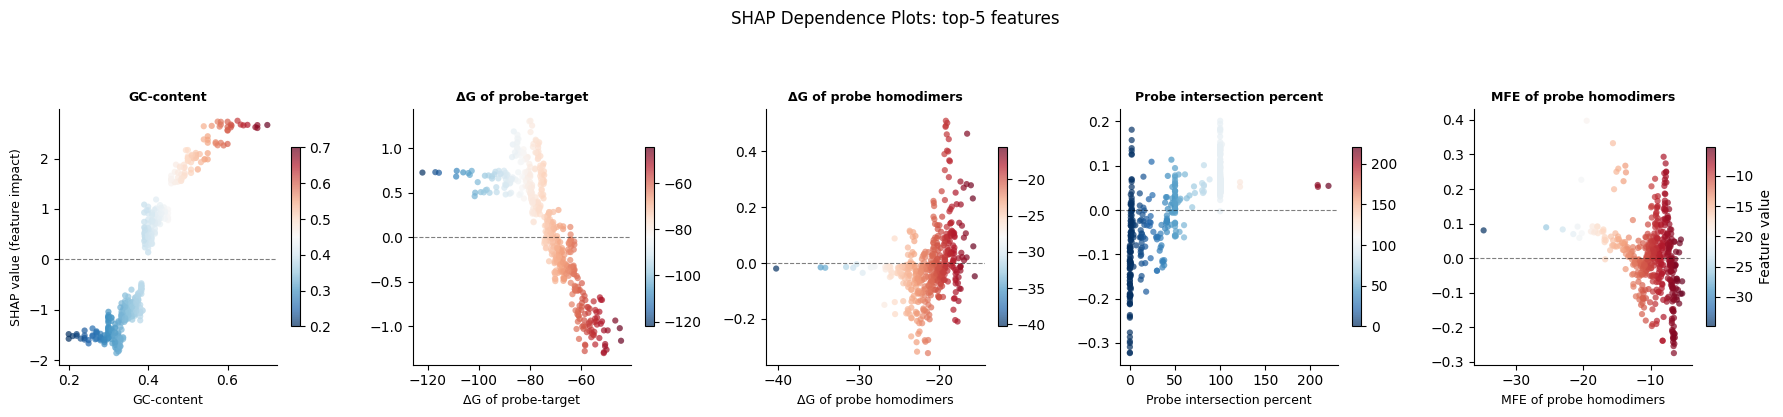

In [ ]:
top5_shap_features = pd.Series(mean_abs_shap, index=SELECTED_FEATURES).nlargest(5).index.tolist()

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, feat in zip(axes, top5_shap_features):
    feat_idx = SELECTED_FEATURES.index(feat)
    feat_vals = X_train_optuna[:, feat_idx]
    shap_feat = shap_values[:, feat_idx]
    sc = ax.scatter(feat_vals, shap_feat, c=feat_vals,
                    cmap="RdBu_r", alpha=0.7, s=20, edgecolors="none")
    ax.axhline(0, color="black", lw=0.8, ls="--", alpha=0.5)
    ax.set_xlabel(feat, fontsize=9)
    ax.set_ylabel("SHAP value (feature impact)" if ax == axes[0] else "", fontsize=9)
    ax.set_title(feat, fontsize=9, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    plt.colorbar(sc, ax=ax, shrink=0.7, label="Feature value" if ax == axes[-1] else "")

fig.suptitle("SHAP Dependence Plots: top-5 features\n",
             fontsize=12, y=1.03)
plt.tight_layout()
#plt.savefig("figs/shap_dependence_top5.png", dpi=300, bbox_inches="tight")
#plt.savefig("figs/svg/shap_dependence_top5.svg", bbox_inches="tight")

In [18]:
df_475 = pd.read_excel('data_test_for_regression.xlsx')
df_475_features = df_475[SELECTED_FEATURES].values
df_475_target = np.log1p(df_475[TARGET_COL].values)

y_475_pred_log = final_model.predict(df_475_features)
spearman_475_log = stats.spearmanr(df_475_target, y_475_pred_log).statistic

print(f"Test on 475 probes - test"
      f"\nSpearman r (log1p): {spearman_475_log:.4f}")

Test on 475 probes - test
Spearman r (log1p): 0.8311
